John S. Anvik, 2025  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ─────────────────────

Load data

In [2]:
MODEL_TYPE <- "True Attention 30s"

data_list <- list()

# TO RUN MODEL ON ALL 11 FOCAL MALES:
folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id_30s"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    data_list <- append(data_list, list(read_csv(file)))
}

# # TO RUN MODEL ON 1 FOCAL MALE:
# file_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id\\YKY_song_type_id_frequency.csv" # TODO: Set file path to data for desired focal male
# data_list <- append(data_list, list(read_csv(file_path)))

Rows: 2169 Columns: 280
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (277): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 556 Columns: 282
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (279): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1033 Columns: 282
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (279): UST, time

In [3]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [4]:
focal_ids <- list()
for (i in seq_along(data_list)) {
    id <- data_list[[i]] %>% pull(ID) %>% unique()
    # print(id)
    focal_ids[[id]] <- id
}
# focal_ids <- list("YKY")
names(data_list) <- focal_ids
# names(data_list) <- "YKY"

In [5]:
# In data (training AND testing), how many of each song type for the focal male?
for (i in seq_along(data_list)) {
    cat("All song types for", data_list[[i]] %>% pull(ID) %>% unique(), ':\n')
    n_ust <- data_list[[i]] %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(data_list[[i]])) %>%
        arrange(desc(percent))
    print(n_ust)
}

All song types for DgTbO :
# A tibble: 29 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1    33   399   18.4 
 2    10   286   13.2 
 3    20   256   11.8 
 4     7   218   10.1 
 5     8   214    9.87
 6   153   176    8.11
 7     1   149    6.87
 8    12   102    4.70
 9    11   101    4.66
10    32    80    3.69
# ℹ 19 more rows
All song types for KLgK :
# A tibble: 20 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1     4    77  13.8  
 2    10    57  10.3  
 3     8    48   8.63 
 4    13    45   8.09 
 5     0    40   7.19 
 6     1    38   6.83 
 7    57    36   6.47 
 8    55    30   5.40 
 9    56    28   5.04 
10     5    27   4.86 
11    15    26   4.68 
12    12    22   3.96 
13    14    22   3.96 
14     9    18   3.24 
15    11    17   3.06 
16    58    11   1.98 
17     6     7   1.26 
18     3     3   0.540
19     7     2   0.360
20    59     2   0.360
All song types for KRDg :
# A tibble: 27 × 3
     UST     n percent
   <dbl> <int>   <dbl>
 1     9   135   13

In [6]:
# View each dataset before selecting columns and dropping na
map(data_list, ~ head(.x, 3))

ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M3_last_30_seconds_shared_songs,M4_last_30_seconds_shared_songs,Attention_on_M1,Attention_on_M2,Attention_on_M3,Attention_on_M4,highest_attention,attention_target_male_number,attention_target_id,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
DgTbO,25,2022-05-13 05:24:14,-1935.691,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
DgTbO,20,2022-05-13 05:24:40,-1909.821,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
DgTbO,1,2022-05-13 05:24:48,-1901.666,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M6_last_30_seconds_shared_songs,Attention_on_M1,Attention_on_M2,Attention_on_M3,Attention_on_M4,Attention_on_M6,highest_attention,attention_target_male_number,attention_target_id,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
KLgK,0,2022-05-19 05:11:00,-2609.898,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
KLgK,0,2022-05-19 05:15:31,-2338.552,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
KLgK,0,2022-05-19 05:16:36,-2273.861,NA,NA,NA,NA,NA,NA,⋯,0,0,0,0,0,0,0,NA,None,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M6_last_30_seconds_shared_songs,Attention_on_M1,Attention_on_M3,Attention_on_M4,Attention_on_M5,Attention_on_M6,highest_attention,attention_target_male_number,attention_target_id,male_number


In [7]:
# Set data types and select input columns
for (i in seq_along(data_list) ){
    focal_male_number <- data_list[[i]] %>% pull(male_number) %>% unique()
    data_list[[i]] <- data_list[[i]] %>% 
        mutate(across(contains("UST"), ~ as.factor(.x)),
            # across(contains("ust"), ~ as.integer(.x)), 
            does_it_match = as.factor(does_it_match),
            number_of_matches = as.integer(number_of_matches)) %>%
        select(
            # Response
            "UST",

            # Own song history (song types)
            sprintf("M%i_1_last_UST", focal_male_number),
            sprintf("M%i_2_last_UST", focal_male_number),
            
            # # Own song history (time since last songs)
            sprintf("time_since_M%i_1_last_song", focal_male_number),
            sprintf("time_since_M%i_2_last_song", focal_male_number),        

            # Who was the highest attention male?
            attention_target_male_number,

            # # Attention target's attention value
            # highest_attention,

            # Count each song type sung recently by highest attention male
            contains("target_window"),
            # Count each song type sung recently by every other male
            contains("others_window")
        )  %>%
        drop_na() # drop any row containing at least one NA value
}


In [8]:
# View each dataset after selecting columns and dropping na
map(data_list, ~ tibble(columns=colnames(.x, 3)))

columns
<chr>
UST
M5_1_last_UST
M6_1_last_UST
M5_2_last_UST
M6_2_last_UST
time_since_M5_1_last_song
time_since_M6_1_last_song
time_since_M5_2_last_song
time_since_M6_2_last_song


In [9]:
# View column names and data types
head(data_list[[2]], 0)

Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
"number of rows of result is not a multiple of vector length (arg 2)"
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
"number of rows of result is not a multiple of vector length (arg 2)"
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
"number of rows of result is not a multiple of vector length (arg 2)"
Warning message in cbind(parts$left, chars$ellip_h, parts$right, deparse.level = 0L):
"number of rows of result is not a multiple of vector length (arg 2)"


UST,M5_1_last_UST,M5_2_last_UST,time_since_M5_1_last_song,time_since_M5_2_last_song,attention_target_male_number,n_ust_1_target_window,n_ust_3_target_window,n_ust_4_target_window,n_ust_5_target_window,⋯,n_ust_156_others_window,n_ust_157_others_window,n_ust_165_others_window,n_ust_166_others_window,n_ust_167_others_window,n_ust_168_others_window,n_ust_169_others_window,n_ust_170_others_window,n_ust_171_others_window,n_ust_172_others_window
<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>


In [10]:
for (i in seq_along(data_list) ){
    print(focal_ids[i])
    cat("Columns:",length(data_list[[i]]), "Rows:", nrow(data_list[[i]]))
    print(glimpse(data_list[[i]]))
}

$DgTbO
[1] "DgTbO"

Columns: 140 Rows: 1031Rows: 1,031
Columns: 140
$ UST                          <fct> 10, 33, 10, 7, 20, 10, 33, 153, 10, 7, 20…
$ M5_1_last_UST                <fct> 33, 10, 33, 20, 7, 20, 10, 15, 33, 10, 7,…
$ M6_1_last_UST                <fct> 33, 10, 33, 20, 7, 20, 10, 15, 33, 10, 7,…
$ M5_2_last_UST                <fct> 8, 33, 10, 33, 20, 7, 20, 153, 153, 33, 1…
$ M6_2_last_UST                <fct> 8, 33, 10, 33, 20, 7, 20, 153, 153, 33, 1…
$ time_since_M5_1_last_song    <dbl> 6.709141, 9.070410, 5.977234, 5.628706, 6…
$ time_since_M6_1_last_song    <dbl> 6.709141, 9.070410, 5.977234, 5.628706, 6…
$ time_since_M5_2_last_song    <dbl> 14.69912, 15.77955, 15.04764, 12.20715, 1…
$ time_since_M6_2_last_song    <dbl> 14.69912, 15.77955, 15.04764, 12.20715, 1…
$ attention_target_male_number <dbl> 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3,…
$ n_ust_1_target_window        <fct> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,…
$ n_ust_3_target_window        <fct> 0, 0, 0, 0, 0, 

In [11]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

In [12]:
for (dataset in data_list) {
    print(nrow(dataset))
}

[1] 1031
[1] 448
[1] 767
[1] 654
[1] 117
[1] 609
[1] 307
[1] 682
[1] 462
[1] 317
[1] 938


In [13]:
models_list <- list()
training_datasets <- list()
testing_datasets <- list()

for (id in focal_ids) {
    if (nrow(data_list[[id]]) > 0) {
        data <- data_list[[id]]
        if (!"UST" %in% names(data)) {
            stop(paste("Column 'UST' missing for ID:", id))
        }
        # train test split
        train_test_split <- initial_split(data, prop = 0.7, strata="UST")

        train_data <- train_test_split %>% training()
        training_datasets[[id]] <- train_data
        test_data <- train_test_split %>% testing()
        testing_datasets[[id]] <- test_data

        # In training data, how many of each song type?
        n_ust <- train_data %>%
            group_by(UST) %>%
            summarize(n = n()) %>%
            mutate(percent = 100*n/nrow(train_data)) %>%
            arrange(percent)
        n_ust

        # use v-fold cross validation to assess model accuracy
        v <- 5
        train_vfold <- vfold_cv(train_data, v=v, strata = "UST")



        # Data preprocessing using a recipe
        recipe <- recipe(UST ~ ., data = train_data) %>%
            step_scale(all_numeric()) %>% # scale all numeric predictors
            step_center(all_numeric()) # center all numeric predictors


        model_tuning <- workflow() %>%
            add_recipe(recipe) %>%
            add_model(model_tuning_spec) %>%

                tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
                # fit(data = train_data) # to train on whole train set with no validation set

        model_tuning

        # Accuracies listed use 5-fold cross validation
        model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
        model_tuning_accuracies

        # plot accuracies of all values of hyperparameters

        ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
            geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
            geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
            labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
            theme(text = element_text(size=20)) +
            scale_fill_gradient(low="white", high="red")

        # Print best hyperparameter values
        best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
        print("Best hyperparameters: (mtry, min_n)")
        print(best_params)

        # retrain model on best parameters
        best_params <- model_tuning %>%
        select_best()
        print("Best Parameters:")
        print(best_params)

        model <- workflow() %>%
            add_recipe(recipe) %>%
            add_model(model_tuning_spec) %>%
            finalize_workflow(best_params) %>%
            # fit_resamples(resamples = train_vfold) # for v-fold cross validation
            fit(data = train_data) # to train on whole train set with no validation set

        models_list[[id]] <- model

    } else {cat(id, "NOT ENOUGH DATA: ", nrow(data_list[[focal_id]]))}
} 
names(models_list) <- focal_ids
names(training_datasets) <- focal_ids
names(testing_datasets) <- focal_ids

→ A | warning: Dropped unused factor level(s) in dependent variable: 5, 13, 25, 154, 156, 157, 158, 160, 162, 164.

There were issues with some computations   A: x1

There were issues with some computations   A: x15

There were issues with some computations   A: x36

There were issues with some computations   A: x66

There were issues with some computations   A: x78

There were issues with some computations   A: x91

There were issues with some computations   A: x120

There were issues with some computations   A: x136

There were issues with some computations   A: x153

There were issues with some computations   A: x171

There were issues with some computations   A: x190

There were issues with some computations   A: x231

There were issues with some computations   A: x253

There were issues with some computations   A: x276

There were issues with some computations   A: x300

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.

[1] "Best hyperparameters: (mtry, min_n)"
2 
8 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    16    20 pre0_mod20_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 5, 13, 25, 156, 157, 158, 162, 164."
→ A | warning: Dropped unused factor level(s) in dependent variable: 3, 58.

There were issues with some computations   A: x1

There were issues with some computations   A: x10

There were issues with some computations   A: x45

There were issues with some computations   A: x91

There were issues with some computations   A: x136

There were issues with some computations   A: x190

There were issues with some computations   A: x253

There were issues with some computations   A: x300

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, and those levels will be removed from the
               averaged result.
               Note that the following number of true events actually occurred for each
               problematic event lev

[1] "Best hyperparameters: (mtry, min_n)"
15 
16 


... (35 outputs left out)

[1] "Best hyperparameters: (mtry, min_n)"
20 
20 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    20    20 pre0_mod25_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 29, 36, 168, 171."


In [14]:
models <- tibble(
    id = focal_ids,
    model = models_list,
    train_data = list(training_datasets),
    test_data = list(testing_datasets)
)

DgTbO 5 6 


Saving 6.67 x 6.67 in image


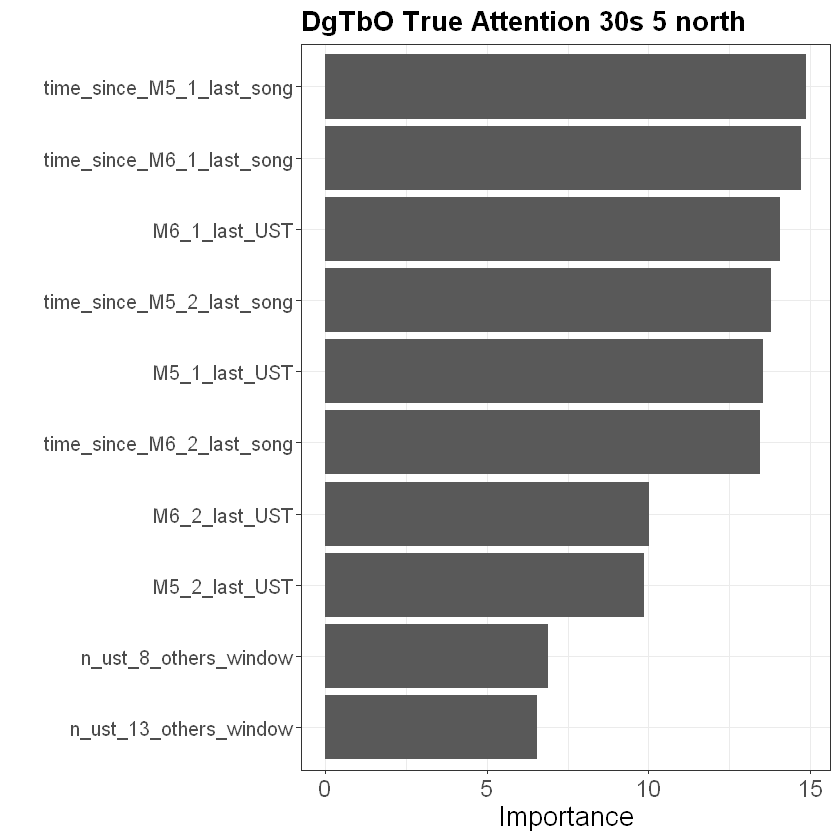

KLgK 5 


Saving 6.67 x 6.67 in image


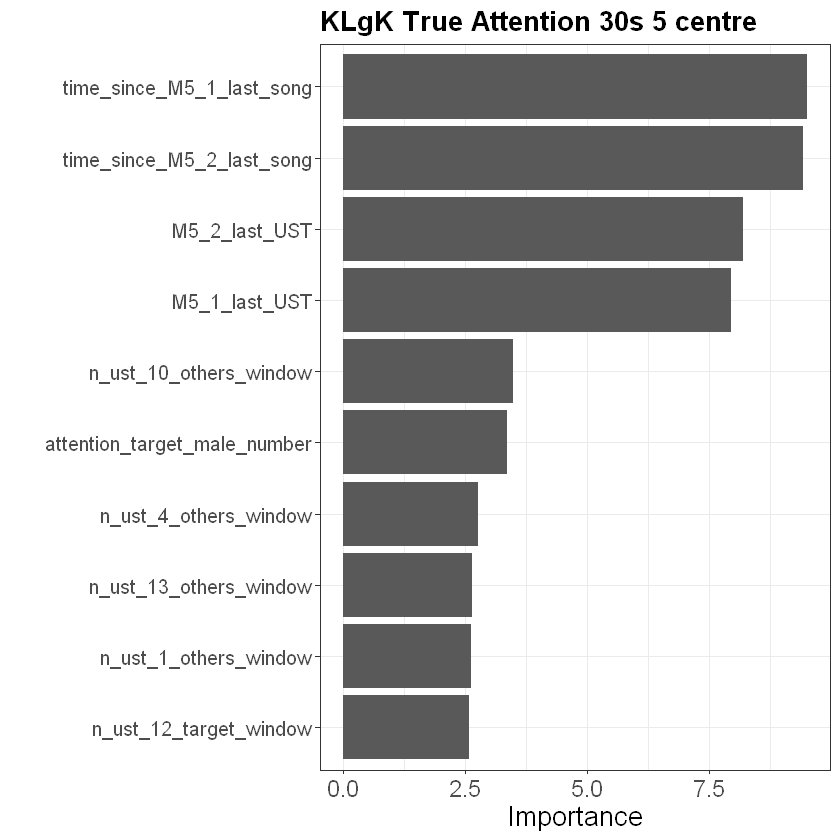

KRDg 2 


Saving 6.67 x 6.67 in image


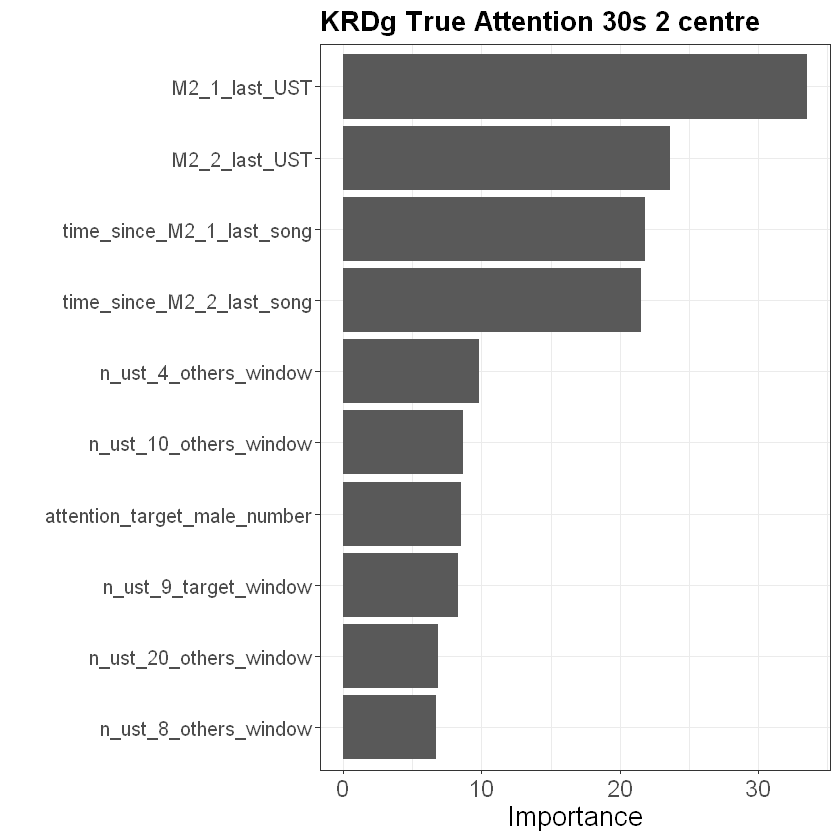

LbOW 1 


Saving 6.67 x 6.67 in image


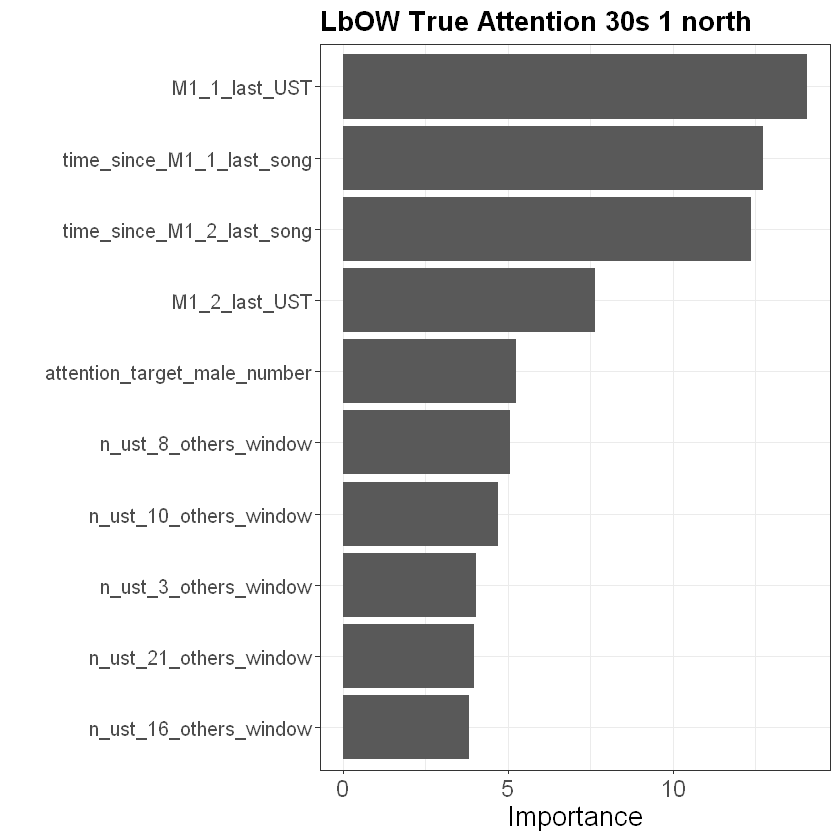

OPR 3 


Saving 6.67 x 6.67 in image


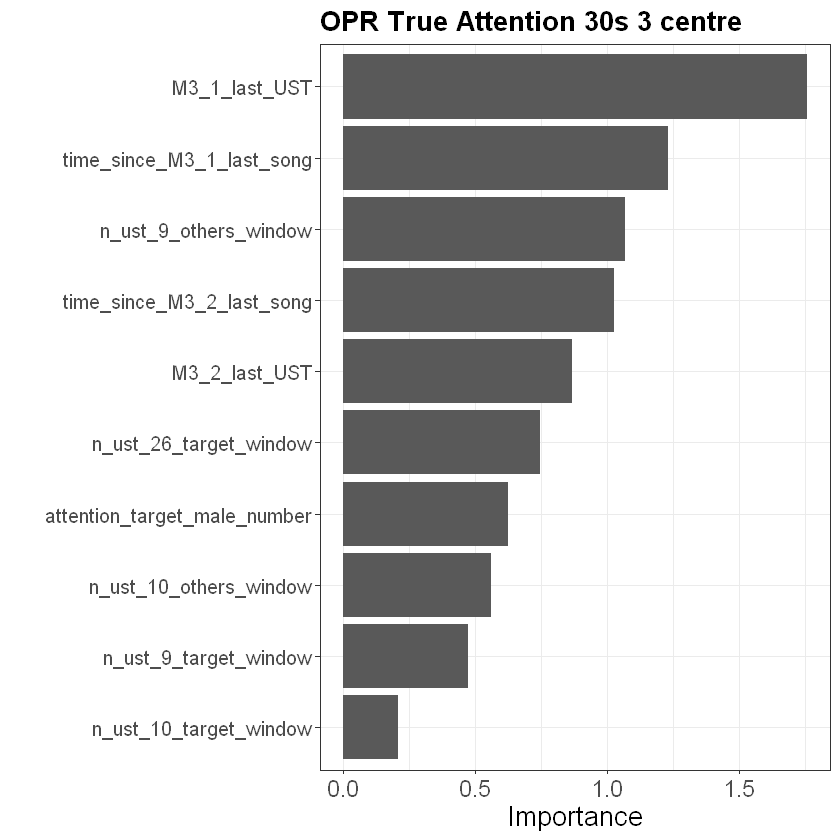

RbDgY 2 


Saving 6.67 x 6.67 in image


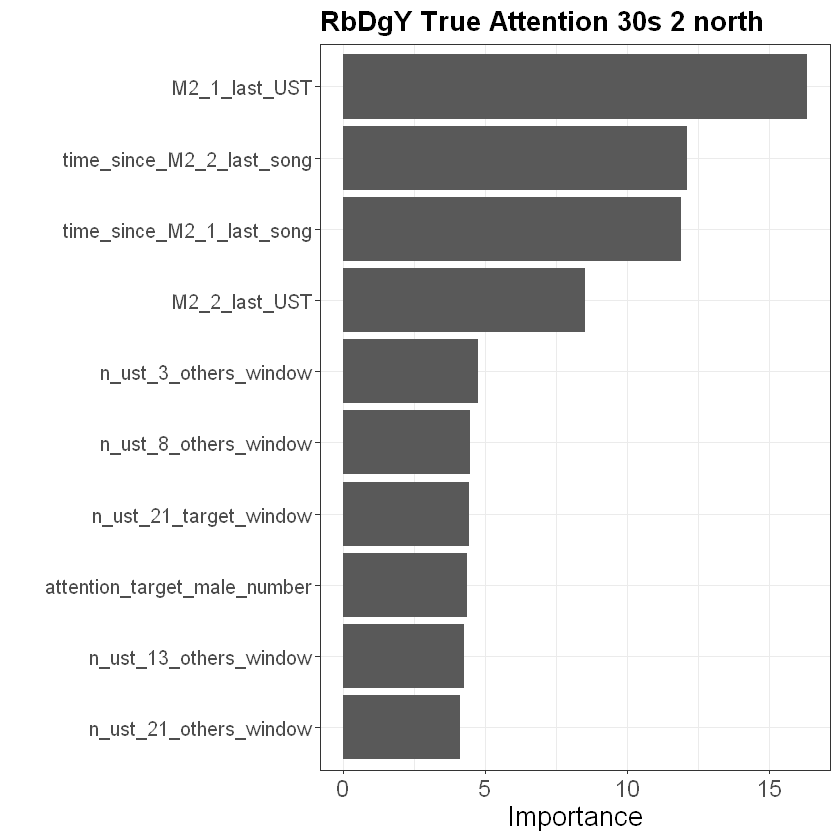

RRO 6 


Saving 6.67 x 6.67 in image


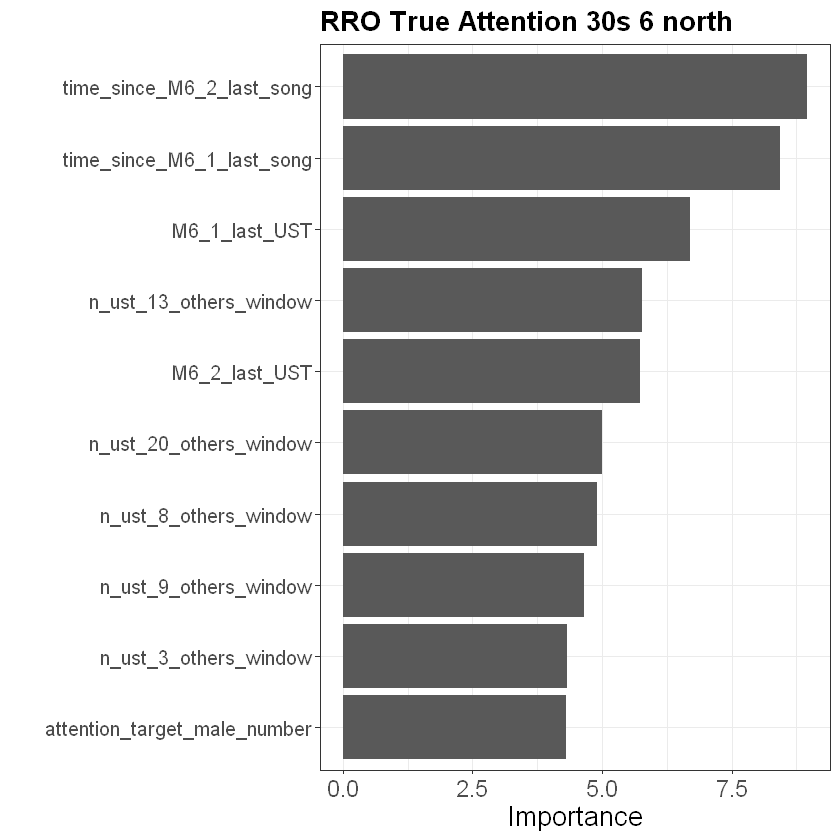

TbTbLg 4 


Saving 6.67 x 6.67 in image


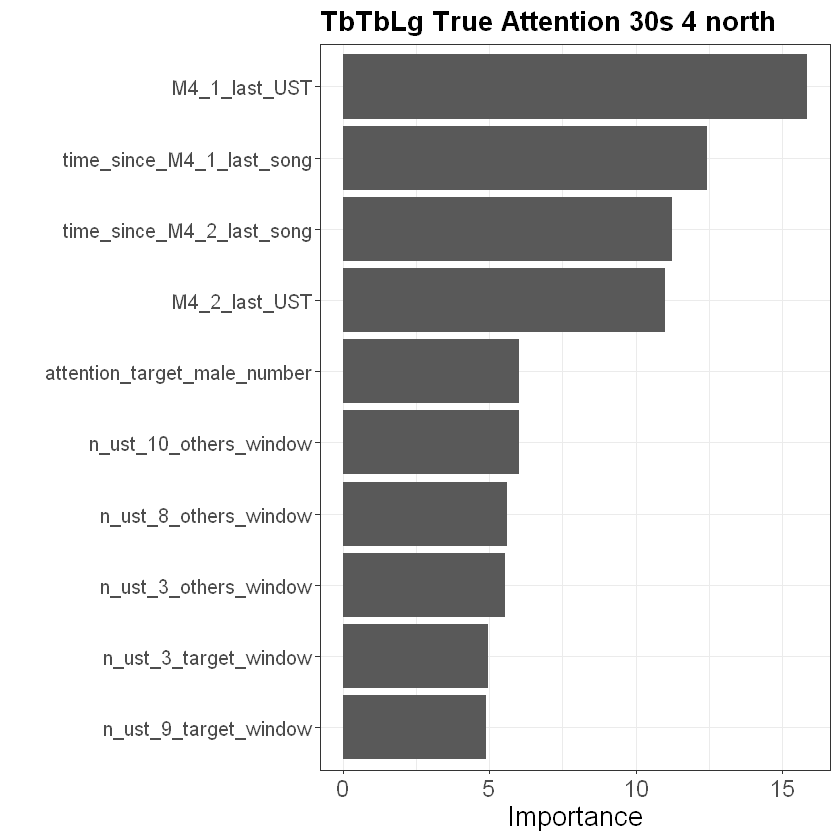

TbWY 1 


Saving 6.67 x 6.67 in image


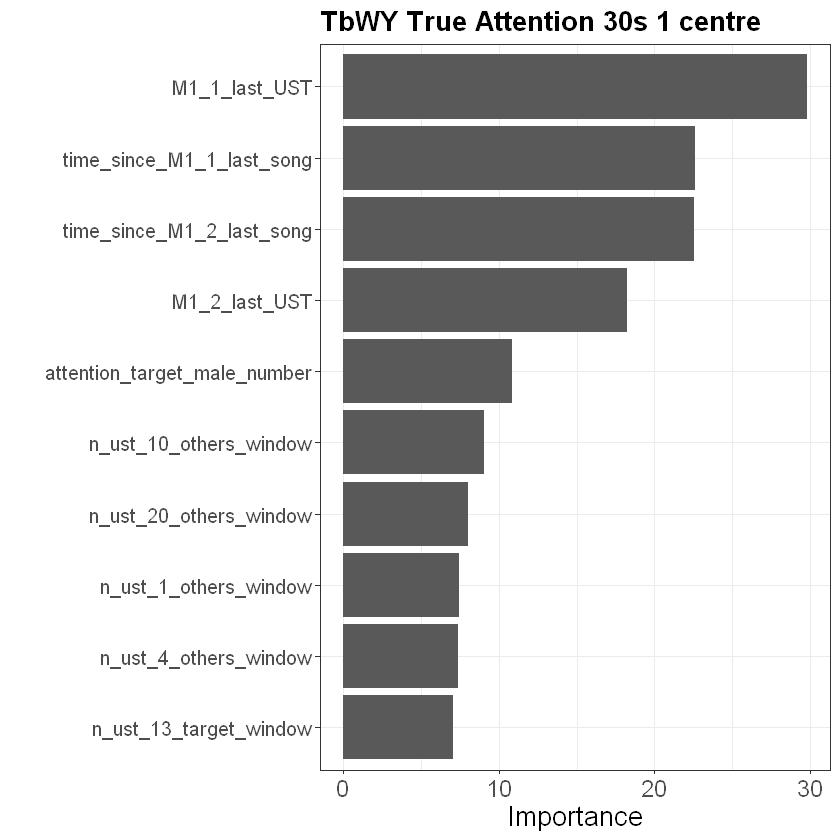

WLpTb 4 


Saving 6.67 x 6.67 in image


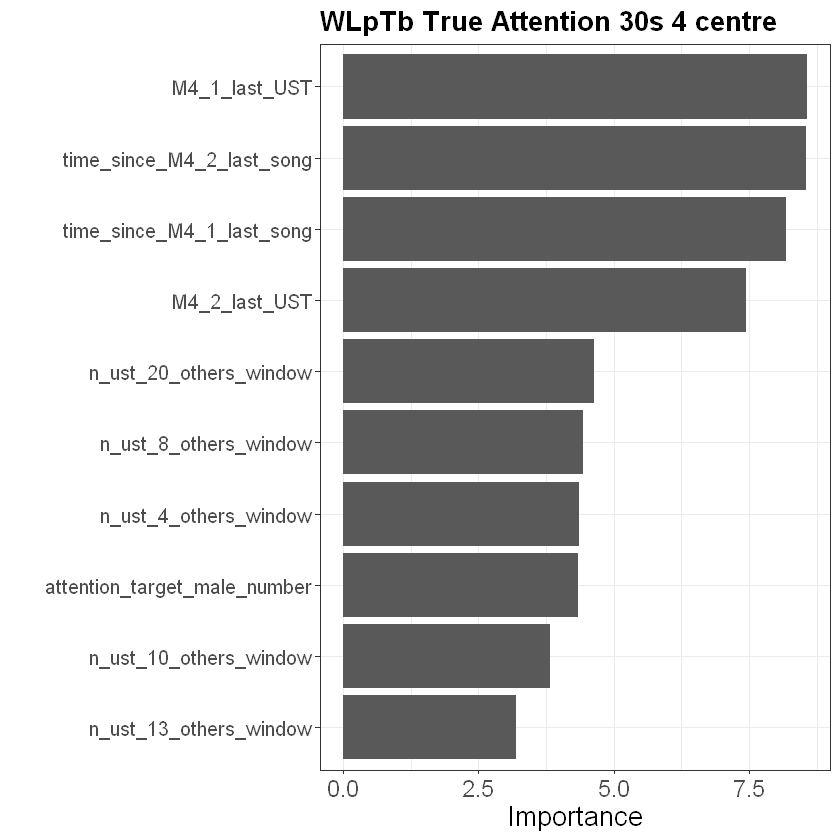

YKY 3 


Saving 6.67 x 6.67 in image


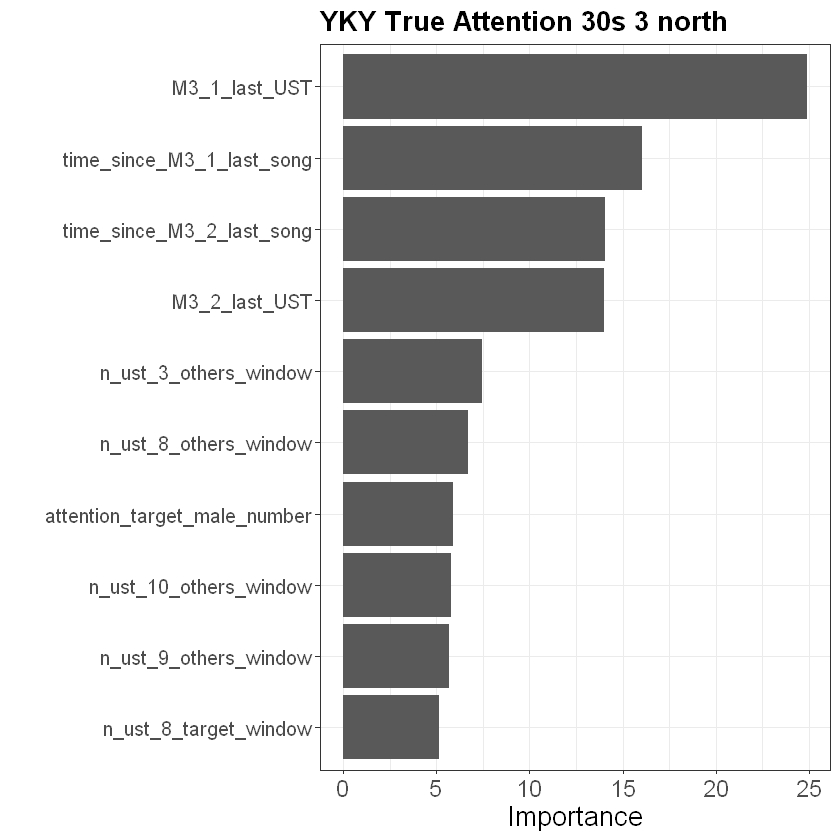

In [15]:
for (id in focal_ids) {
  model <- models_list[[id]]
  male_number <- focal_males %>% filter(ID == id) %>% pull(male_number)
  neighbourhood <- focal_males %>% filter(ID == id) %>% pull(neighbourhood)
  importance_chart <- model %>% extract_fit_engine() %>% vip(num_features=10) +
    labs(title=paste(id, MODEL_TYPE, male_number, neighbourhood)) +
    theme_bw() + # Starting with a clean theme
    theme(
      axis.text.x = element_text(size = 14),       # X-axis tick labels
      axis.text.y = element_text(size = 12),       # Y-axis tick labels
      axis.title.x = element_text(size = 16),      # X-axis title
      axis.title.y = element_text(size = 16),      # Y-axis title
      plot.title = element_text(size = 16, face = "bold"), # Main plot title
      legend.text = element_text(size = 12),       # Legend labels
      legend.title = element_text(size = 14)       # Legend title
    )
  print(importance_chart)
  cat(id, male_number, '\n')
  ggsave(paste(MODEL_TYPE, id, "importance.png"), plot=importance_chart)
}


In [16]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
# Return the accuracy of models

all_test_accuracies = tibble()
all_song_accuracies = tibble()

for (id in focal_ids) {
    View(id)
    test_data <- testing_datasets[[id]]
    model <- models_list[[id]]
    test_predictions <- model %>% predict(test_data) %>%
        bind_cols(test_data)
    test_accuracy <- test_predictions %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        rename(estimated_accuracy = .estimate) %>%
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, estimated_accuracy, model)
        # TODO: Add other features such as repertoire size, size of territory, neighbourhood
        #%>% pull(.estimate) %>% round(3)
    View(test_accuracy)
    all_test_accuracies <- all_test_accuracies %>% bind_rows(test_accuracy)

    test_song_accuracies <- test_predictions %>% group_by(UST) %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        arrange(desc(.estimate)) %>% 
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, UST, .estimate, model) %>% 
        rename(estimated_accuracy = .estimate) %>%
        left_join(n_ust %>% select(UST, n), by = "UST")
    View(test_song_accuracies)
    all_song_accuracies <- all_song_accuracies %>% bind_rows(test_song_accuracies)

    # View(test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Precision = correct positive predictions / total positive predictions
    # View(test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Recall = correct positive predictions / total positive test set observations

    confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
    print(confusion_matrix)
}

[1] "DgTbO"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
DgTbO,0.2371795,True Attention 30s


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
DgTbO,33,0.5000000,True Attention 30s,NA
DgTbO,20,0.3157895,True Attention 30s,11
DgTbO,8,0.2857143,True Attention 30s,52
DgTbO,7,0.2564103,True Attention 30s,NA
DgTbO,10,0.2291667,True Attention 30s,34
DgTbO,4,0.2222222,True Attention 30s,NA
DgTbO,1,0.1000000,True Attention 30s,57
DgTbO,6,0.0000000,True Attention 30s,NA
DgTbO,11,0.0000000,True Attention 30s,NA


[1] "KLgK"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
KLgK,0.2,True Attention 30s


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
KLgK,4,0.72727273,True Attention 30s,NA
KLgK,8,0.41666667,True Attention 30s,52
KLgK,10,0.20000000,True Attention 30s,34
KLgK,13,0.12500000,True Attention 30s,27
KLgK,1,0.09090909,True Attention 30s,57
KLgK,0,0.00000000,True Attention 30s,2
KLgK,5,0.00000000,True Attention 30s,19
KLgK,6,0.00000000,True Attention 30s,NA
KLgK,9,0.00000000,True Attention 30s,49


... (24 outputs left out)

[1] "YKY"

ID,estimated_accuracy,model
<chr>,<dbl>,<chr>
YKY,0.2198582,True Attention 30s


ID,UST,estimated_accuracy,model,n
<chr>,<fct>,<dbl>,<chr>,<int>
YKY,21,0.7200000,True Attention 30s,67
YKY,1,0.5454545,True Attention 30s,57
YKY,9,0.5000000,True Attention 30s,49
YKY,166,0.5000000,True Attention 30s,53
YKY,10,0.2000000,True Attention 30s,34
YKY,8,0.1904762,True Attention 30s,52
YKY,27,0.1428571,True Attention 30s,49
YKY,3,0.0500000,True Attention 30s,42
YKY,0,0.0000000,True Attention 30s,2


          Truth
Prediction  0  1  4  5  6  7  8 10 11 12 13 15 20 25 30 32 33 153 154 155 156
       0    0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       1    0  2  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0   0   0   0   0
       4    0  0  2  0  0  0  0  2  2  0  0  0  1  0  0  1  1   0   0   0   0
       5    0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       6    0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       7    0  1  0  0  0 10  4  8  0  4  0  1  3  0  0  3  3   1   0   0   0
       8    0  1  1  0  0  1 10  2  0  4  0  2  2  0  0  1  5   0   0   0   0
       10   0  3  1  0  1  4  8 11  2  1  0  0  8  0  0  7  5   8   0   0   0
       11   0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       12   0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  2   0   0   0   0
       13   0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0   0   0   0   0
       15   0  0  0  0  0  0  0  0  0  0  0  0  

In [17]:
filename <- paste0("data/results/", MODEL_TYPE, "_test_accuracies.csv")
print(filename)
write_csv(all_test_accuracies, filename)

filename <- paste0("data/results/", MODEL_TYPE, "_song_accuracies.csv")
print(filename)
write_csv(all_song_accuracies, filename)

[1] "data/results/True Attention 30s_test_accuracies.csv"
[1] "data/results/True Attention 30s_song_accuracies.csv"
